Tutorial: inertia relief of a stick aircraft model, MSC Nastran example HA144A
===

The forward-swept-wing (FSW) airplane with canard of the MSC Nastran example
HA144A, "FSW Airplane in Level Flight" (Rodden and Johnson 1994, pp. 181-205),
is a half model of beams and concentrated masses in trimmed 1 g level flight.
The airplane is free: the aerodynamic loads are balanced by the inertia of the
rigid-body motion, and Nastran reports the displacements relative to the
reference support (SUPORT) at GRID 90, in heave and pitch. This is a static
analysis with inertia relief, and this notebook repeats it with pyfe3d:

1. the structure is built with `BeamC` elements exactly from the bulk data,
   with the rigid bars (RBAR) of the wing masses as a transformation of the
   degrees of freedom;
2. the mass properties are checked against the grid point weight generator,
   and the stiffness model against the published displacements, using the
   nodal loads that are in equilibrium with the published bar forces;
3. the published doublet-lattice box forces are transferred to the beam nodes
   with Nastran's beam splines (SPLINE2), implemented here, and, as an
   alternative, with the coupling of Gryszka and Castro (2026); the inertia
   relief of `pyfe3d.solver.apply_inertia_relief` (Barnett et al. 1995),
   verified in `tut-inertia-relief.ipynb`, is compared with the published
   results;
4. the aerodynamic loads are computed with the vortex lattice method of
   AeroSandbox (Sharpe 2021), trimmed for level flight at the conditions of
   subcases 1 and 2 of the example, transferred with the same splines, and
   the inertia relief is compared again.

What is exactly reproducible is asserted to the printed precision of the
listing: the mass properties, the displacements given the bar forces, the
global equilibrium, $\boldsymbol{\Phi}^\top \boldsymbol{F}_{tot} =
\boldsymbol{0}$ with zero reactions at the reference support, and, with the
published box forces and the splines of Nastran, all the published bar forces
and displacements. The results with the alternative load transfer and with
the AeroSandbox loads are compared with the level of agreement stated in each
section.

References:

- Rodden, W. P., Johnson, E. H., *MSC/NASTRAN Aeroelastic Analysis User's
  Guide, Version 68*, The MacNeal-Schwendler Corporation, Los Angeles, 1994.
  Splines: Eqs. 2-22 to 2-25 (pp. 33-35) and 2-44 to 2-59 (pp. 38-43),
  Section 3.3 (pp. 106-108). Example HA144A: description pp. 181-188, input Listing 7-1 (pp. 189-195),
  sorted bulk data Listing 7-2 (pp. 196-197), output Listing 7-3 (pp.
  198-205).
- MSC Software, *MSC Nastran 2020 Quick Reference Guide*, Newport Beach,
  2020. Bulk Data entry SPLINE2, pp. 3137-3138.
- Gryszka, M., Castro, S. G. P., *Angled spar battery-wing system for large
  all-electric aircraft*, engrXiv preprint, 2026,
  https://engrxiv.org/preprint/view/7893/version/10171
- Barnett, A. R., Widrick, T. W., Ludwiczak, D. R., *Closed-Form Static
  Analysis with Inertia Relief and Displacement-Dependent Loads Using a
  MSC/NASTRAN DMAP Alter*, NASA TM-106836, 1995,
  https://ntrs.nasa.gov/citations/19950013233
- Sharpe, P. D., *AeroSandbox: A Differentiable Framework for Aircraft Design
  Optimization*, Master's thesis, Massachusetts Institute of Technology, 2021,
  https://dspace.mit.edu/handle/1721.1/140023

This notebook needs `aerosandbox` (version 4.2.10 was used) for the last
part. The structural parts are also checked by
`tests/test_inertia_relief_ha144a.py`, whose model and data this notebook
imports.

Units, axes and published data
---

The example uses the lb-ft-s system: the CONM2 entries are weights in lb,
converted to masses in slug by `PARAM,WTMASS,0.031081` $= 1/g$ (p. 192), with
$g = 32.174$ ft/s$^2$. The basic coordinate system has $x$ aft, $y$ to the
right wing and $z$ up; GRID 97 is the nose at $x = 0$, GRID 90 the
reference point at $x = 15$ ft (Figure 7-1, p. 181, and Listing 7-2).

The published values used below were read from the page images of the
listing, since a text extraction shifts some rows of the tables against the
grid and element numbers. They are stored in
`tests/test_inertia_relief_ha144a.py`, except those of subcase 1, which only
this notebook uses. The box forces are checked here for consistency: each
force equals the pressure times the box area, 6.25 ft$^2$ (checked while
transcribing), the forces sum to the weight of the half model, 8000 lb, and
their moment about the centre of gravity vanishes (the trim).

In [1]:
import os
import sys
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

from pyfe3d import DOF
from test_inertia_relief_ha144a import (
    WTMASS, G_ACC, GRIDS, CBARS, PBARS, CONM2, RBARS, MO_PUB, IS_PUB,
    XCG_PUB, BAR_PUB, DISP_PUB, BOX_FORCES_SC2, box_points, build_model,
    weight_generator, bar_forces, loads_from_bar_forces, transfer_loads,
    weight_loads, solve_inertia_relief, SPLINE2, CORD2R, spline2_loads,
    box_moments, resultant)

# subcase 1, Mach 0.9, q = 40 psf, the quasi-rigid airplane
# box normal forces, Listing 7-3, pp. 199-200, boxes 1000-1007 and 1100-1131
BOX_FORCES_SC1 = np.array([
    1.196130E+03, 2.175811E+02, 8.883241E+01, 7.096516E+01,
    9.470382E+02, 1.563349E+02, 6.773703E+01, 6.250663E+01,
    -3.000173E+02, -1.329865E+01, 8.216619E+00, 5.635094E+00,
    -1.869569E+00, -4.253911E-01, 1.135240E+01, 7.515286E+00,
    1.049276E+03, 1.124095E+02, 3.016934E+01, 1.173226E+01,
    7.831523E+02, 2.530540E+02, 7.268033E+01, 2.304776E+01,
    6.081699E+02, 2.663550E+02, 1.161488E+02, 4.008963E+01,
    4.804525E+02, 2.304277E+02, 1.301754E+02, 5.613909E+01,
    3.667927E+02, 1.795658E+02, 1.164818E+02, 6.184264E+01,
    2.404014E+02, 1.152592E+02, 8.074072E+01, 5.120200E+01])
# displacements relative to GRID 90, p. 203: GRID: (T3, R1, R2)
DISP_PUB[1] = {
    97: (-6.176795E-03, 0., -6.320098E-04), 98: (-8.566984E-04, 0., -3.320095E-04),
    99: (-9.633963E-04, 0., 3.960283E-04), 100: (-1.065960E-02, 0., 1.688768E-03),
    110: (-2.420829E-03, 7.440053E-04, 2.557247E-03),
    111: (3.972288E-03, 7.440053E-04, 2.557247E-03),
    112: (-8.813946E-03, 7.440053E-04, 2.557247E-03),
    120: (2.554698E-02, 1.262856E-03, 3.255694E-03),
    121: (3.368622E-02, 1.262856E-03, 3.255694E-03),
    122: (1.740775E-02, 1.262856E-03, 3.255694E-03)}
# bar forces, p. 204; the torques of elements 110 and 120 are printed
# truncated in subcase 1 ("45978E+04", "479167E+03") and are not used (nan)
BAR_PUB[1] = {
    100: (-1.820093E+04, -2.140187E+04, 6.401870E+02, 0.),
    101: (-9.094947E-13, -1.500000E+04, 1.500000E+03, 0.),
    102: (-1.500000E+04, -1.820094E+04, 6.401870E+02, 0.),
    103: (-2.140187E+04, -4.323508E+04, 2.183321E+03, 0.),
    110: (5.796102E+04, 3.544555E+04, 3.899794E+03, np.nan),
    120: (3.026060E+04, 4.318098E+03, 2.246687E+03, np.nan)}
BOX_FORCES = {1: BOX_FORCES_SC1, 2: BOX_FORCES_SC2}
Q_SC = {1: 40., 2: 1200.}     # dynamic pressures, psf, TRIM 1 and 2
MACH = 0.9
W = 8000.                     # lb, weight of the half model

canard_pts, wing_pts = box_points()
box_pts = np.vstack((canard_pts, wing_pts))
xcg = 15. + XCG_PUB
for sc, F in BOX_FORCES.items():
    Mcg = (F*(xcg - box_pts[:, 0])).sum()
    print('subcase %d: sum of box forces %.4f lb, canard %.1f lb, '
          'moment about the c.g. %.1e lb ft' % (sc, F.sum(), F[:8].sum(), Mcg))
    assert np.isclose(F.sum(), W, rtol=1e-7)
    assert abs(Mcg) < 1e-2

subcase 1: sum of box forces 7999.9997 lb, canard 2807.1 lb, moment about the c.g. -7.6e-03 lb ft
subcase 2: sum of box forces 8000.0000 lb, canard 2662.7 lb, moment about the c.g. 1.8e-04 lb ft


The structural model
---

The bulk data of Listing 7-2 (pp. 196-197) translate into pyfe3d as follows
(`build_model()` in the test module):

| Bulk data | Content | pyfe3d |
|---|---|---|
| GRID 90-100 | fuselage, $x$ = 0 to 30 ft | nodes |
| GRID 110, 120 | wing elastic axis at 50% chord, 30 deg forward sweep | nodes |
| GRID 111, 112, 121, 122 | wing masses, 2.5 ft forward and aft of the axis | nodes, dependent through RBAR |
| CBAR 100-103 (PBAR 100) | fuselage, $A$ = 2.0, $I_1$ = 0.173611, $I_2$ = 0.15, $J$ = 0.5 ft$^2$, ft$^4$ | `BeamC` |
| CBAR 110, 120 (PBAR 101) | wing, $A$ = 1.5, $I_1$ = 0.173611, $I_2$ = 2.0, $J$ = 0.462963 | `BeamC` |
| MAT1 1 | $E$ = 1.44e9 psf, $G$ = 5.40e8 psf | `BeamProp.E`, `G` |
| CONM2 | 1500 lb at GRID 97-100, 600 lb (forward) and 400 lb (aft) at 111, 121 and 112, 122 | diagonal mass matrix, translations |
| RBAR 111-122 | rigid bars from GRID 110 and 120, all six components dependent | transformation $\boldsymbol{T}$ |
| SPC1 1 | symmetry: $v$, $r_x$, $r_z$ of the fuselage grids, and $u$ of GRID 90 | `bfix` |
| SUPORT 90 35 | reference support: $w$ and $r_y$ of GRID 90 | `bref` |

Choices:

- *Element orientation.* The CBAR orientation vector $(0, 0, 1)$ makes plane 1
  vertical; in `BeamC`, a vector in the element plane $xy$ normal to $z$
  makes the element $z$ axis vertical, so that $I_1$ = `Iyy`, $I_2$ = `Izz`.
- *Shear.* The PBAR entries have no shear factors $K_1$, $K_2$, i.e. the bars
  are rigid in shear; `BeamC` is a Timoshenko element, so `G12` and `G13` are
  set to $10^6 E$, while the torsional stiffness stays `G*J`.
- *Rigid bars.* The dependent degrees of freedom of a rigid bar from $A$ to
  $B$, $\boldsymbol{r} = \boldsymbol{x}_B - \boldsymbol{x}_A$, are
  $\boldsymbol{u}_B = \boldsymbol{u}_A + \boldsymbol{\theta}_A \times
  \boldsymbol{r}$ and $\boldsymbol{\theta}_B = \boldsymbol{\theta}_A$, i.e.
  $\boldsymbol{u} = \boldsymbol{T} \boldsymbol{u}_{ind}$ over all degrees of
  freedom. The reduced matrices $\boldsymbol{T}^\top \boldsymbol{K}_{C0}
  \boldsymbol{T}$ and $\boldsymbol{T}^\top \boldsymbol{M} \boldsymbol{T}$ and
  loads $\boldsymbol{T}^\top \boldsymbol{F}$ are those of the RBAR, exactly:
  the masses at the offset grids give the coupled translational and
  rotational inertia at GRID 110 and 120, and a load at an offset grid acts on
  the elastic axis with its moment. Stiff beams instead of the rigid bars
  would only approximate this, with an ill-conditioned stiffness matrix.
  Displacements at the dependent grids are recovered with $\boldsymbol{T}$.
- *Constraints.* Fuselage and wing lie in the plane $z = 0$; the symmetry
  constraints leave two rigid-body modes, heave and pitch, which the
  reference support at GRID 90 removes. The beams have no mass (no density
  on MAT1, no NSM on PBAR).

degrees of freedom: 66 in total, 42 independent, 16 constrained (SPC1), 2 reference (SUPORT)


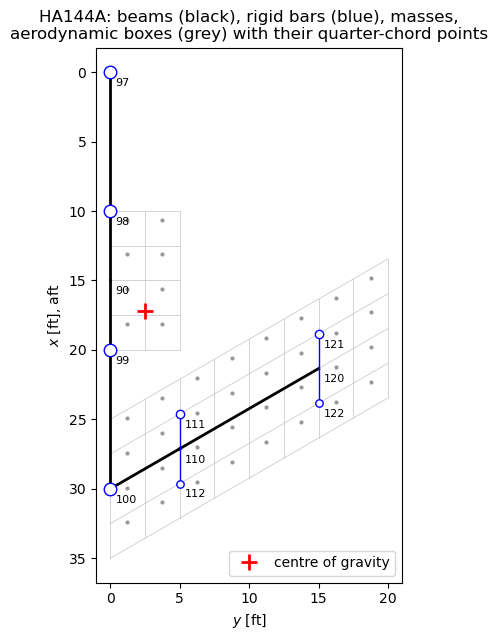

In [2]:
model = build_model()
idx, ncoords = model['idx'], model['ncoords']
print('degrees of freedom: %d in total, %d independent, %d constrained (SPC1), '
      '%d reference (SUPORT)' % (model['N'], model['ind'].sum(),
                                 model['bfix'].sum(), model['bref'].sum()))

fig, ax = plt.subplots(figsize=(6, 6.5))
for i, p in enumerate(box_pts):
    ax.plot(p[1], p[0], '.', color='0.6', ms=4)
# box outlines of the two CAERO1 panels
for (x1, x12, x4, y4, ns, nc) in ((10., 10., 10., 5., 2, 4),
                                   (25., 10., 13.45299, 20., 8, 4)):
    for j in range(ns + 1):
        eta = j/ns
        ax.plot([eta*y4]*2, [x1 + eta*(x4 - x1), x1 + eta*(x4 - x1) + x12],
                color='0.8', lw=0.6)
    for i in range(nc + 1):
        ax.plot([0, y4], [x1 + i/nc*x12, x4 + i/nc*x12], color='0.8', lw=0.6)
for eid, (pid, ga, gb) in CBARS.items():
    a, b = ncoords[idx[ga]], ncoords[idx[gb]]
    ax.plot([a[1], b[1]], [a[0], b[0]], 'k-', lw=2)
for gb, ga in RBARS.items():
    a, b = ncoords[idx[ga]], ncoords[idx[gb]]
    ax.plot([a[1], b[1]], [a[0], b[0]], 'b-', lw=1)
for g, w in CONM2.items():
    p = ncoords[idx[g]]
    ax.plot(p[1], p[0], 'o', ms=4 + w/300, mfc='w', mec='b')
for g in GRIDS:
    p = ncoords[idx[g]]
    ax.annotate(str(g), (p[1], p[0]), xytext=(4, -10), textcoords='offset points',
                fontsize=8)
ax.plot(2.5, xcg, 'r+', ms=12, mew=2, label='centre of gravity')
ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_xlabel('$y$ [ft]')
ax.set_ylabel('$x$ [ft], aft')
ax.set_title('HA144A: beams (black), rigid bars (blue), masses,\n'
             'aerodynamic boxes (grey) with their quarter-chord points')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Check 1: mass properties
---

The grid point weight generator (p. 198) prints the rigid-body mass matrix
about GRID 90, $\boldsymbol{M}_O = \boldsymbol{\Phi}_O^\top \boldsymbol{M}
\boldsymbol{\Phi}_O$ in weight units, with $\boldsymbol{\Phi}_O$ the six
geometric rigid-body modes about GRID 90 (translations and rotations), the
centre of gravity and the inertia about it, I(S). The weights are $4 \times
1500 + 2 \times (600 + 400) = 8000$ lb; the centre of gravity, from the
static moments, is at $\bar{x} = (1500 (0 + 10 + 20 + 30) + 600 (24.61325 +
18.83975) + 400 (29.61325 + 23.83975))/8000 = 17.181625$ ft, i.e. 2.181625 ft
aft of GRID 90, and the pitch inertia about it is $I_{yy} = \sum_i w_i (x_i -
\bar{x})^2 = 8.928944 \times 10^5$ lb ft$^2$. The text of the example rounds
these to 2.182 ft and 892,894 lb ft$^2$ (p. 184).

In [3]:
MO, m, xcg_rel, IS = weight_generator(model)
np.set_printoptions(linewidth=120)
print('MO about GRID 90 [lb, lb ft, lb ft^2]:\n', np.array2string(MO, precision=6))
print('weight %.6f lb, c.g. %.6f ft aft of and %.6f ft outboard of GRID 90'
      % (m, xcg_rel[0], xcg_rel[1]))
print('I(S) [lb ft^2]:\n', np.array2string(IS, precision=4))
print('pitch inertia about the c.g.: %.6e lb ft^2 (published 8.928944e+05)' % IS[1, 1])
xbar = (1500*(0 + 10 + 20 + 30) + 600*(24.61325 + 18.83975)
        + 400*(29.61325 + 23.83975))/8000
assert np.isclose(xbar - 15, XCG_PUB, rtol=1e-12)
assert np.allclose(MO, MO_PUB, rtol=0, atol=1e-6*abs(MO_PUB).max())
assert np.isclose(m, 8000., rtol=1e-14)
assert np.isclose(xcg_rel[0], 2.181625, rtol=1e-12)
assert np.isclose(IS[1, 1], 8.928944e5, rtol=1e-6)
assert np.allclose(IS, IS_PUB, rtol=0, atol=1e-6*abs(IS_PUB).max())

MO about GRID 90 [lb, lb ft, lb ft^2]:
 [[   8000.             0.             0.             0.             0.        -20000.      ]
 [      0.          8000.             0.             0.             0.         17453.      ]
 [      0.             0.          8000.         20000.        -17453.             0.      ]
 [      0.             0.         20000.        250000.       -145662.5            0.      ]
 [      0.             0.        -17453.       -145662.5       930970.255625       0.      ]
 [ -20000.         17453.             0.             0.             0.       1180970.255625]]
weight 8000.000000 lb, c.g. 2.181625 ft aft of and 2.500000 ft outboard of GRID 90
I(S) [lb ft^2]:
 [[ 200000.      102030.          -0.    ]
 [ 102030.      892894.3545      -0.    ]
 [     -0.          -0.     1092894.3545]]
pitch inertia about the c.g.: 8.928944e+05 lb ft^2 (published 8.928944e+05)


Check 2: the stiffness model against the published displacements
---

Fuselage and wing form a tree: given the loads, the bar forces follow from
statics alone. Conversely, the nodal loads that are in equilibrium with the
published bar forces (p. 204) are the assembled element end forces, and
applied to the model they must give the published displacements relative to
GRID 90 (pp. 203-204), if the stiffness, the geometry and the rigid bars are
those of Nastran. These nodal loads contain the aerodynamic loads as Nastran's
splines distribute them and the inertia loads, and are balanced.

Nastran's CBAR forces are the bending moments of plane 1 at the ends A and
B, $M_{1A}$ and $M_{1B}$, the shear $V_1 = -d M_1/d x$ and the torque $T$.
With the element $z$ axis vertical, they are, from the internal forces
`finte` of `BeamC` (`bar_forces()`): $M_{1A}$ = `finte[4]`, $M_{1B}$ =
`-finte[10]`, $V_1$ = `finte[8]` and $T$ = `finte[9]`. $M_1$ is positive
when the top fibre is in compression: element 101 has $M_{1B} = -1.5 \times
10^4$ lb ft and the stress $+8.64 \times 10^4$ psf at the top point C, $y = z =
1$ ft (p. 205).

Subcases 2 (Mach 0.9, $q$ = 1200 psf) and 3 (Mach 1.3, $q$ = 1151 psf) are
used; subcase 1 is not, since its wing torques are printed truncated.

In [4]:
for sc in (2, 3):
    f = loads_from_bar_forces(model, BAR_PUB[sc])
    out = solve_inertia_relief(model, f)
    u = out['ufull']
    upub = np.array([DISP_PUB[sc][g] for g in DISP_PUB[sc]])
    ufe = np.array([u[DOF*idx[g] + np.array([2, 3, 4])] for g in DISP_PUB[sc]])
    err = abs(ufe - upub).max()/abs(upub).max()
    bf = bar_forces(model, u)
    errf = max(abs(bf[e] - BAR_PUB[sc][e]).max() for e in bf)
    print('subcase %d: rigid-body accelerations %s, reactions at GRID 90 %s'
          % (sc, np.array2string(out['acc'], precision=1),
             np.array2string(out['Rref'], precision=1)))
    print('  max |u - u_pub|/max |u_pub| = %.1e, max |bar force - published| = %.1e'
          % (err, errf))
    if sc == 2:
        print('  %5s %14s %14s %14s %14s' % ('GRID', 'w pyfe3d', 'w Nastran',
                                             'r_y pyfe3d', 'r_y Nastran'))
        for g, (w_, rx_, ry_) in DISP_PUB[sc].items():
            print('  %5d %14.6e %14.6e %14.6e %14.6e' % (
                g, u[DOF*idx[g] + 2], w_, u[DOF*idx[g] + 4], ry_))
        print('  nodal loads [lb] in equilibrium with the published bar forces:')
        for g in (97, 98, 99, 100, 110, 120):
            print('    GRID %d: F_z = %9.2f, net of the weight %9.2f' % (
                g, f[DOF*idx[g] + 2], f[DOF*idx[g] + 2] + {110: 1000., 120: 1000.}.get(g, 1500.)))
    assert abs(out['acc']).max() < 1e-6
    assert err < 2e-6
    assert errf < 2e-6*6.2e4

subcase 2: rigid-body accelerations [-4.6e-07 -2.1e-07], reactions at GRID 90 [-7.3e-12  1.0e-10]
  max |u - u_pub|/max |u_pub| = 1.3e-07, max |bar force - published| = 5.9e-03
   GRID       w pyfe3d      w Nastran     r_y pyfe3d    r_y Nastran
     97  -6.264163e-03  -6.264164e-03  -6.385623e-04  -6.385624e-04
     98  -8.785403e-04  -8.785404e-04  -3.385621e-04  -3.385622e-04
     99  -1.007080e-03  -1.007080e-03   4.156861e-04   4.156862e-04
    100  -1.125761e-02  -1.125761e-02   1.789539e-03   1.789539e-03
    110  -2.503216e-03  -2.503219e-03   2.716038e-03   2.716038e-03
    111   4.286879e-03   4.286876e-03   2.716038e-03   2.716038e-03
    112  -9.293311e-03  -9.293314e-03   2.716038e-03   2.716038e-03
    120   2.737436e-02   2.737436e-02   3.470037e-03   3.470037e-03
    121   3.604945e-02   3.604945e-02   3.470037e-03   3.470037e-03
    122   1.869926e-02   1.869926e-02   3.470037e-03   3.470037e-03
  nodal loads [lb] in equilibrium with the published bar forces:
    GRID 9

The model reproduces the published displacements to the 7 printed digits,
and the bar forces back. The nodal loads net of the weights show how
Nastran's splines (SPLINE2, p. 182) distribute the aerodynamic loads in
subcase 2: the canard, 2662.7 lb, goes to GRID 98 and 99 only, 2228.8 lb and
434.0 lb (the lever rule, see below); the wing, 5337.3 lb, then puts
$-55.5 - 434.0 = -489.5$ lb on GRID 99 and $-234.3$ lb on GRID 100, and the
rest on the wing grids. A different load transfer gives
different bar forces in the fuselage aft of GRID 90 and in the wing, as shown
below.

Inertia relief with the published aerodynamic loads
---

The inertia relief is computed with `pyfe3d.solver.apply_inertia_relief`, through
`solve_inertia_relief()` of the test, which applies the transformation of
the rigid bars, see also `tut-inertia-relief.ipynb` and the user guide page
[Inertia relief](inertia_relief.rst): with the reference support `bref` (here $w$ and
$r_y$ of GRID 90), the rigid-body modes $\boldsymbol{\Phi}$ follow from the
stiffness matrix (Barnett et al. 1995, Eq. (19)), the rigid-body
accelerations from $\boldsymbol{\Phi}^\top \boldsymbol{M} \boldsymbol{\Phi}
\ddot{\boldsymbol{\alpha}} = \boldsymbol{\Phi}^\top \boldsymbol{F}_{ext}$
(Eqs. (21)-(22)), and the displacements relative to the reference support
from the loads plus the d'Alembert forces (Eqs. (23)-(24)). The external
loads are the aerodynamic loads and the weights, $-m g$ along $z$ at each
mass; for a trimmed airplane they are balanced and $\ddot{\boldsymbol{\alpha}}
= \boldsymbol{0}$. Nastran's trim with `URDD3` $= -1$ (1 g) and `URDD5` $= 0$
(p. 183) is the same balance: the inertia forces of the 1 g vertical
acceleration equal the weights.

**Load transfer: the beam splines of Nastran.** Nastran interpolates the
deflections of the aerodynamic grid points from those of the structural
grids, $\boldsymbol{u}_k = \boldsymbol{G}_{kg} \boldsymbol{u}_g$, and
transfers the aerodynamic loads with the transpose, $\boldsymbol{F}_g =
\boldsymbol{G}_{kg}^\top \boldsymbol{F}_k$, which does the same virtual work
(Rodden and Johnson 1994, Eqs. 2-22 to 2-25, pp. 33-35). HA144A uses linear
splines, SPLINE2 (Quick Reference Guide, pp. 3137-3138; theory in Rodden and
Johnson 1994, pp. 38-43): a beam along the $y$ axis of a coordinate system,
with bending and torsion and the flexibility ratio DTOR $= EI/GJ$, which
passes through the deflections of the structural grids, and rigid arms along
its $x$ axis, i.e. a rigid chord perpendicular to the elastic axis (p. 42). A
point at the spline coordinates $(x, y)$ deflects by $w = w_b(y) - x
\psi(y)$ and rotates by $\varphi_x = w_b'(y)$ and $\psi(y)$, with $w_b$ and
$\psi$ the bending deflection and the twist of the spline. `spline2_matrix()`
of the test module builds $\boldsymbol{G}_{kg}$ from the fundamental
solutions of the infinite beam, the rigid-body terms and the attachment
flexibilities (Eqs. 2-44 to 2-59); its deflection kernel is that of p. 43,
and the kernels of the rotations follow from the same solutions (derived
here, checked by the exact transfer of the resultants below). The bulk data
(Listing 7-1, pp. 192-193; Listing 7-2, cards 50-57, 69-70, 73-76):

| Spline | Boxes | SET1 grids | Axis | DZ | DTOR | DTHX | DTHY |
|---|---|---|---|---|---|---|---|
| SPLINE2 1501, canard | 1000-1007 | 98, 99 | CORD2R 1: hinge line, $x$ = 12.5 ft, along $y$ | 0 | 1 | 1 | -1 |
| SPLINE2 1601, wing | 1100-1131 | 99, 100, 111, 112, 121, 122 | CORD2R 2: elastic axis from GRID 100, 30 deg forward sweep | 0 | 1 | -1 | -1 |

DZ $= 0$ makes the spline pass through the deflections of the grids; a
negative DTHX or DTHY disconnects the slope or the twist (Remark 3, p.
3138), so the wing spline uses the deflections $w$ of its six grids only, and
the canard spline the deflections of GRID 98 and 99 and, through a flexible
attachment, their roll (pp. 182-183).

**Moments.** The aerodynamic grid point of a doublet-lattice box is its
centre (p. 20), and Nastran applies there the normal force and the moment of
the force, which acts at the quarter chord, about the midchord (p. 186). The
box forces are moved to the box centres with their moments,
$(\boldsymbol{x}_j - \boldsymbol{x}_{0j}) \times \boldsymbol{F}_j$
(`box_moments()`), and the spline carries both to the structure through its
rigid arms. Since the spline reproduces the rigid-body motions of the grids
exactly (the terms $a_0 + a_1 y - a_2 x$), the transfer conserves the
resultant normal force and its moments about the in-plane axes, by virtual
work (derived here, checked below). The in-plane forces are not transferred,
as in Nastran, whose splines interpolate the normal deflections (Section 3.3,
p. 106).

In [5]:
fw = weight_loads(model)
c_ref = 10.                               # ft, reference chord
xcg_pt = np.array([xcg, 0., 0.])
qc_pts = box_pts                          # quarter-chord points
cen_pts = np.vstack(box_points(0.5))      # box centres, aerodynamic grid points


def aero_loads_spline(Fz, pts=qc_pts):
    r'''Normal forces at the points pts, moved to the box centres with their
    moments and transferred with SPLINE2 1501 and 1601'''
    return spline2_loads(model, cen_pts, Fz, box_moments(pts, cen_pts, Fz))


def resultant_aero(Fz, pts):
    F3 = np.zeros((len(Fz), 3))
    F3[:, 2] = Fz
    return np.concatenate((F3.sum(axis=0), np.cross(pts - xcg_pt, F3).sum(axis=0)))


resA = {}
for sc in (1, 2):
    F = BOX_FORCES[sc]
    fa = aero_loads_spline(F)
    # resultant force and moment about the c.g. conserved by the transfer
    dres = abs(resultant(model, fa, xcg_pt) - resultant_aero(F, qc_pts)).max()
    out = solve_inertia_relief(model, fa + fw)
    u, bf = out['ufull'], bar_forces(model, out['ufull'])
    errf = max(np.nanmax(abs(bf[e] - BAR_PUB[sc][e])) for e in bf)
    upub = np.array([DISP_PUB[sc][g] for g in DISP_PUB[sc]])
    ufe = np.array([u[DOF*idx[g] + np.array([2, 3, 4])] for g in DISP_PUB[sc]])
    erru = abs(ufe - upub).max()/abs(upub).max()
    print('subcase %d: |resultant transferred - resultant of the box forces| = %.1e, '
          'accelerations %s' % (sc, dres, np.array2string(out['acc'], precision=1)))
    print('  max |bar force - published| = %.1e, max |u - u_pub|/max |u_pub| = %.1e'
          % (errf, erru))
    print('  element 103: M1A %.6e M1B %.6e V1 %.6e | published %.6e %.6e %.6e'
          % (tuple(bf[103][:3]) + tuple(BAR_PUB[sc][103][:3])))
    print('  w of GRID 120 (tip of the elastic axis) %.6e | published %.6e'
          % (u[DOF*idx[120] + 2], DISP_PUB[sc][120][0]))
    # the canard spline is the lever rule between GRID 98 and 99
    w99 = (canard_pts[:, 0] - 10.)/10.
    assert np.isclose(fa[DOF*idx[98] + 2], ((1 - w99)*F[:8]).sum(), rtol=1e-12)
    Fc = np.r_[F[:8], np.zeros(32)]
    assert np.isclose(aero_loads_spline(Fc)[DOF*idx[99] + 2], (w99*F[:8]).sum(),
                      rtol=1e-12)
    assert dres < 1e-10*W*c_ref
    assert abs(out['acc']).max() < 1e-5*G_ACC
    assert abs(out['Rref']).max() < 1e-9*W
    # all published bar forces and displacements, to the printed digits
    assert errf < 2e-6*6.2e4
    assert erru < 2e-6
    resA[sc] = out
    # forces applied at the quarter chord, without the moments about the box centres
    oq = solve_inertia_relief(model, spline2_loads(model, qc_pts, F) + fw)
    bq = bar_forces(model, oq['ufull'])
    print('  forces at the quarter chord instead: element 103 M1B %+.2e, V1 %+.2e, '
          'w of GRID 120 %+.2e (relative to Nastran)'
          % (bq[103][1]/BAR_PUB[sc][103][1] - 1, bq[103][2]/BAR_PUB[sc][103][2] - 1,
             oq['ufull'][DOF*idx[120] + 2]/DISP_PUB[sc][120][0] - 1))

subcase 1: |resultant transferred - resultant of the box forces| = 4.5e-11, accelerations [-1.8e-06 -2.7e-07]
  max |bar force - published| = 7.6e-03, max |u - u_pub|/max |u_pub| = 1.1e-07
  element 103: M1A -2.140187e+04 M1B -4.323508e+04 V1 2.183321e+03 | published -2.140187e+04 -4.323508e+04 2.183321e+03
  w of GRID 120 (tip of the elastic axis) 2.554698e-02 | published 2.554698e-02
  forces at the quarter chord instead: element 103 M1B -8.78e-04, V1 -1.74e-03, w of GRID 120 -2.89e-04 (relative to Nastran)
subcase 2: |resultant transferred - resultant of the box forces| = 8.0e-11, accelerations [1.6e-07 6.5e-09]
  max |bar force - published| = 6.4e-03, max |u - u_pub|/max |u_pub| = 1.2e-07
  element 103: M1A -2.271239e+04 M1B -4.598023e+04 V1 2.326783e+03 | published -2.271239e+04 -4.598023e+04 2.326784e+03
  w of GRID 120 (tip of the elastic axis) 2.737436e-02 | published 2.737436e-02
  forces at the quarter chord instead: element 103 M1B -3.97e-05, V1 -7.85e-05, w of GRID 120 -1.9

With the splines of the deck, the published box forces reproduce all the
published bar forces and displacements to the printed digits, in both
subcases: the remaining differences, below $2 \times 10^{-6}$ of the
largest values, are those of the 7 printed digits of the box forces. The
transferred loads have the resultant force and moment of the box forces to
round-off, the airplane is in trim (accelerations at the level of the
rounding), and the reactions at GRID 90 vanish. The canard spline reduces to
the lever rule between GRID 98 and 99, $F_{99} = \sum_j F_j (x_j - 10)/10$
and $F_{98} = \sum_j F_j - F_{99}$, as both grids lie on the canard root at
the same spline coordinate $y = 0$ and the roll goes to the symmetry
constraints.

Two details matter at this precision. First, the forces must be applied as
Nastran does, at the box centres with their moments: applying them at the
quarter chord through the spline conserves the resultant as well, but the
rigid arms, perpendicular to the swept elastic axis, are not along the flow,
and element 103 changes by up to $2 \times 10^{-3}$. Second, the ratio
DTOR changes the transfer when the grids lie off the spline axis: with DTOR
$= 0.5$ or $2$ instead of $1$, the shear of element 103 in subcase 2 changes
by about $\pm 5$%, although the guide states that DTOR has no effect with
zero attachment flexibility (p. 108).

The alternative: the transfer of Gryszka and Castro (2026)
---

Section 2.3.5 (p. 8) of Gryszka and Castro (2026) transfers the forces of the
aerodynamic mesh to the structural nodes with the inverse-distance weights of
their Eq. (5),

$$
w_{ij} = \frac{1/d_{ij}^2}{\sum_{k=1}^{n_{points}} 1/d_{kj}^2}
$$

over the $n_{points}$ nearest nodes $i$ of each aerodynamic point $j$, found
with `scipy.spatial.cKDTree`, applied to the translational degrees of freedom
only. The weights sum to one, which conserves the resultant force, but not
its moment. In the wingbox model of the paper the nodes surround the
aerodynamic points; in a stick model all nodes lie on the beam axes or on the
rigid bars, and the moment of each force about its nodes is lost. Here the
moment of the offset, $w_{ij} (\boldsymbol{x}_j - \boldsymbol{x}_i) \times
\boldsymbol{F}_j$, is added to the rotational degrees of freedom of node $i$
(`moments=True` of `transfer_loads()`), which conserves force and moment for
any weights; this term is an addition of this notebook. The forces are
applied at the quarter-chord points, the canard boxes are transferred to GRID
98 and 99 ($n_{points} = 2$), and the wing boxes to GRID 99, 100, 111, 112,
121 and 122 ($n_{points} = 3$), the grids of the splines; the loads at the
offset grids reach the elastic axis through the rigid bars.

In [6]:
WING_GRIDS = [99, 100, 111, 112, 121, 122]


def aero_loads_idw(Fz, pts=qc_pts, moments=True, npw=3):
    F3 = np.zeros((len(Fz), 3))
    F3[:, 2] = Fz
    can = (pts[:, 0] < 21.) & (pts[:, 1] < 5.)
    return (transfer_loads(model, pts[can], F3[can], [98, 99], 2, moments)
            + transfer_loads(model, pts[~can], F3[~can], WING_GRIDS, npw, moments))


resC = {}
for sc in (1, 2):
    for moments in (False, True):
        fa = aero_loads_idw(BOX_FORCES[sc], moments=moments)
        out = solve_inertia_relief(model, fa + fw)
        bf = bar_forces(model, out['ufull'])
        print('subcase %d, %-18s: accelerations w_dd = %+.2e ft/s^2, '
              'r_y_dd = %+.2e rad/s^2; element 101 V1 = %.2f lb, M1B = %.1f lb ft'
              % (sc, 'forces and moments' if moments else 'forces only',
                 out['acc'][0], out['acc'][1], bf[101][2], bf[101][1]))
        # equilibrium and reference support, both variants
        assert abs(out['Phi'].T @ out['ftot']).max() < 1e-9*W
        assert abs(out['Rref']).max() < 1e-9*W
        if moments:
            resC[sc] = out
            assert abs(resultant(model, fa, xcg_pt)
                       - resultant_aero(BOX_FORCES[sc], qc_pts)).max() < 1e-9*W*c_ref
            assert abs(out['acc']).max() < 1e-5*G_ACC
            assert np.allclose(bf[101], [0., -1.5e4, 1.5e3, 0.], rtol=0, atol=1e-6*1.5e4)
        else:
            assert abs(out['acc'][1]) > 0.1

subcase 1, forces only       : accelerations w_dd = -7.36e-01 ft/s^2, r_y_dd = -3.37e-01 rad/s^2; element 101 V1 = 1229.69 lb, M1B = -12296.9 lb ft
subcase 1, forces and moments: accelerations w_dd = -1.85e-06 ft/s^2, r_y_dd = -2.74e-07 rad/s^2; element 101 V1 = 1500.00 lb, M1B = -15000.0 lb ft
subcase 2, forces only       : accelerations w_dd = -7.81e-01 ft/s^2, r_y_dd = -3.58e-01 rad/s^2; element 101 V1 = 1213.25 lb, M1B = -12132.5 lb ft
subcase 2, forces and moments: accelerations w_dd = +1.63e-07 ft/s^2, r_y_dd = +6.54e-09 rad/s^2; element 101 V1 = 1500.00 lb, M1B = -15000.0 lb ft


With the forces only, the transferred loads have a pitching moment about the
centre of gravity that the aerodynamic loads do not have, and the airplane
accelerates in pitch (about $-0.3$ rad/s$^2$): the inertia forces change
the bar forces, e.g. the shear of element 101 is no longer the weight of
GRID 97. With the moments of the offsets, the accelerations vanish to the
rounding of the published box forces, the reactions at GRID 90 vanish, and
element 101 carries $V_1 = 1500$ lb and $M_{1B} = -1.5 \times 10^4$ lb ft, as
published. The rest of the structure differs from Nastran by the
distribution of the loads, by 0.1-25% (column C of the comparison below):
the inverse-distance weights put positive loads on GRID 99 and 100, where the
wing spline puts negative ones (Check 2), and a part of the canard load on
GRID 99 with a nodal moment at GRID 98.

Neither transfer drops the moments of the forces: SPLINE2 carries them
through its rigid arms, Eq. (5) needs the added offset term. Eq. (5) itself
weights the forces only (p. 8, "this weight needs to be added to three
entries ... corresponding to the first three degrees of freedom").

The vortex lattice method of AeroSandbox
---

Following Gryszka and Castro (2026, Section 2.3.4, pp. 7-8), the aerodynamic
loads are computed with the vortex lattice method of
AeroSandbox, with a Prandtl-Glauert correction applied directly to the forces,
$\boldsymbol{F} = \boldsymbol{F}_{inc}/\sqrt{1 - M^2}$. The output of
`VortexLatticeMethod` per panel is a force, $\boldsymbol{F} = \rho
(\boldsymbol{V} \times \boldsymbol{l}) \Gamma$ at the midpoint of the bound
vortex, `vortex_centers`, at the quarter chord of the panel, and no couple:
`moments_geometry` is only the moment of these forces about `xyz_ref`
(`aerosandbox/aerodynamics/aero_3D/vortex_lattice_method.py`, version
4.2.10, lines 227-229 and 327-336). Its transfer must therefore carry the
moments $\boldsymbol{r} \times \boldsymbol{F}$ of the forces: they are moved
to the box centres with their moments and transferred with SPLINE2 1501 and
1601, exactly as the published box forces, so that the comparison isolates
the aerodynamic model. Only the normal force, along $z$, is transferred, as
in Nastran; the in-plane components, the induced drag, are not. The geometry is that of p. 181 and of the CAERO1 entries:

- wing: chord 10 ft, half span 20 ft, leading edge from $(25, 0)$ to
  $(13.45299, 20)$ ft (30 deg forward sweep), incidence 0.1 deg (in Nastran,
  the downwash W2GJ = 0.001745 rad of the wing boxes, p. 182), modelled as
  the twist of its sections;
- canard: chord 10 ft, half span 5 ft, leading edge at $x = 10$ ft, no sweep,
  all-moving about its quarter chord, $x = 12.5$ ft, by the angle $\delta$
  (ELEV), modelled as the twist of its sections (AeroSandbox twists about the
  leading edge, so the leading edge is placed on the circle about the quarter
  chord);
- flat plates (the camber line of a symmetric airfoil), coplanar at $z = 0$,
  mirrored about $y = 0$; the panels are exactly the boxes of CAERO1: 8 x 4 on
  the wing and 2 x 4 on the canard, uniform spacing, with the vortex centres at
  the box quarter chords;
- fuselage aerodynamics neglected, as in the example (p. 181).

The vortex lattice method is linear, as the doublet lattice: the loads of
the right half are $\boldsymbol{F}(\alpha, \delta) = \boldsymbol{F}_0 +
\alpha \boldsymbol{F}_\alpha + \delta \boldsymbol{F}_\delta$, from three runs.
The velocity of the runs only sets a reference dynamic pressure, by which the
forces are scaled to $q$ of the subcase. The trim of level flight solves
for $\alpha$ and $\delta$ such that the lift equals the weight, 8000 lb, and
the pitching moment about the centre of gravity vanishes. A uniform factor on
the forces, as the Prandtl-Glauert correction, changes the trim angles but
not the trimmed loads.

In [7]:
import aerosandbox as asb

flat = asb.Airfoil('naca0010')       # symmetric: flat camber line


def make_airplane(delta_deg):
    ys = np.linspace(0., 20., 9)
    wing = asb.Wing(name='wing', symmetric=True, xsecs=[
        asb.WingXSec(xyz_le=[25. + (13.45299 - 25.)*y/20., y, 0.], chord=10.,
                     twist=0.1, airfoil=flat) for y in ys])
    d = np.deg2rad(delta_deg)
    canard = asb.Wing(name='canard', symmetric=True, xsecs=[
        asb.WingXSec(xyz_le=[12.5 - 2.5*np.cos(d), y, 2.5*np.sin(d)], chord=10.,
                     twist=delta_deg, airfoil=flat) for y in (0., 2.5, 5.)])
    return asb.Airplane(name='HA144A', xyz_ref=[xcg, 0., 0.], wings=[wing, canard])


def vlm_forces(alpha_deg, delta_deg):
    r"""Vortex centres and forces of the right half, ordered as the boxes
    1000-1007 and 1100-1131, Prandtl-Glauert corrected, per unit dynamic
    pressure"""
    op = asb.OperatingPoint(velocity=100., alpha=alpha_deg)
    vlm = asb.VortexLatticeMethod(make_airplane(delta_deg), op,
                                  spanwise_resolution=1, chordwise_resolution=4,
                                  spanwise_spacing_function=np.linspace,
                                  chordwise_spacing_function=np.linspace)
    vlm.run()
    pts, F = vlm.vortex_centers, vlm.forces_geometry
    # match each box quarter-chord point to its vortex centre
    order = [np.argmin(((pts[:, :2] - p[:2])**2).sum(axis=1)) for p in box_pts]
    return pts[order], F[order]/op.dynamic_pressure()/np.sqrt(1 - MACH**2)


p0, F0 = vlm_forces(0., 0.)
pa, Fa = vlm_forces(1., 0.)
pd, Fd = vlm_forces(0., 1.)
print('max distance vortex centre - box quarter-chord point: %.1e ft (x, y), '
      '%.1e ft (z, the incidence of 0.1 deg)'
      % (abs(p0[:, :2] - box_pts[:, :2]).max(), abs(p0[:, 2]).max()))
assert abs(p0[:, :2] - box_pts[:, :2]).max() < 1e-3
f0, fa_, fd_ = F0[:, 2], (Fa - F0)[:, 2]*180/np.pi, (Fd - F0)[:, 2]*180/np.pi

S, c = 200., 10.


def coeffs(fz):
    r"""Lift coefficient and pitching moment coefficient about GRID 90 (nose
    up positive), per unit dynamic pressure"""
    return fz.sum()/S, (fz*(15. - box_pts[:, 0])).sum()/(S*c)


# rigid derivatives of the listing, Mach 0.9, p. 198-199 (NACA axes, C_L = -C_Z)
nastran = {'0': (8.420787E-03, -6.008128E-03), 'alpha': (5.070976, -2.870932),
           'delta': (2.461395E-01, 5.715300E-01)}
beta = np.sqrt(1 - MACH**2)
print('%-6s %9s %13s %12s %11s %16s %15s' % ('', 'C_L VLM', 'C_L VLM*beta', 'C_L Nastran',
                                           'C_m,90 VLM', 'C_m,90 VLM*beta', 'C_m,90 Nastran'))
for key, fz in (('0', f0), ('alpha', fa_), ('delta', fd_)):
    CL, Cm = coeffs(fz)
    print('%-6s %9.5f %13.5f %12.5f %11.5f %16.5f %15.5f' % (
        key, CL, CL*beta, nastran[key][0], Cm, Cm*beta, nastran[key][1]))

max distance vortex centre - box quarter-chord point: 1.2e-05 ft (x, y), 1.4e-02 ft (z, the incidence of 0.1 deg)
         C_L VLM  C_L VLM*beta  C_L Nastran  C_m,90 VLM  C_m,90 VLM*beta  C_m,90 Nastran
0        0.01444       0.00629      0.00842    -0.00975         -0.00425        -0.00601
alpha    8.86343       3.86348      5.07098    -4.62481         -2.01591        -2.87093
delta    0.59639       0.25996      0.24614     0.96478          0.42054         0.57153


The rigid derivatives (per rad) of the doublet-lattice model are those
printed for the rigid, splined airplane (pp. 198-199). The Prandtl-Glauert
factor $1/\sqrt{1 - 0.81} = 2.29$ applied to all forces overestimates the
lift-curve slope at Mach 0.9 for this low-aspect-ratio configuration, by about
75% for $C_{L_\alpha}$ and 140% for the canard of aspect ratio 1, whose
effectiveness hardly changes with Mach number; the incompressible values
(columns "VLM*beta") are 24% below and 6% above the doublet lattice. As stated
above, this factor changes the trim angles but not the trimmed loads.

**Trim.** For each subcase, $q (\boldsymbol{f}_0 + \alpha
\boldsymbol{f}_\alpha + \delta \boldsymbol{f}_\delta)$ is trimmed such that
$\sum F_z = W$ and $\sum F_z (\bar{x} - x) = 0$. The trim angles of
Nastran's rigid airplane follow from its rigid derivatives, with the moment
about the centre of gravity $C_{m,cg} = C_{m,90} + C_L (\bar{x} - 15)/c$; the
published elastic trim is ANGLEA and ELEV of the listing (pp. 199, 201).

In [8]:
def trim(fz0, fza, fzd, q):
    # moments of the forces at the vortex centres p0
    A = q*np.array([[fza.sum(), fzd.sum()],
                    [(fza*(xcg - p0[:, 0])).sum(), (fzd*(xcg - p0[:, 0])).sum()]])
    b = np.array([W - q*fz0.sum(), -q*(fz0*(xcg - p0[:, 0])).sum()])
    return np.linalg.solve(A, b)


def trim_nastran_rigid(q):
    CLreq = W/(q*S)
    A = np.array([[nastran['alpha'][0], nastran['delta'][0]],
                  [nastran['alpha'][1], nastran['delta'][1]]])
    b = np.array([CLreq - nastran['0'][0],
                  -CLreq*XCG_PUB/c - nastran['0'][1]])
    return np.linalg.solve(A, b)


elastic = {1: (1.691910E-01, 4.924567E-01), 2: (1.373013E-03, 1.932495E-02)}
FB = {}
for sc, q in Q_SC.items():
    al, de = trim(f0, fa_, fd_, q)
    FB[sc] = q*(f0 + al*fa_ + de*fd_)
    assert np.isclose(FB[sc].sum(), W, rtol=1e-12)
    assert abs((FB[sc]*(xcg - p0[:, 0])).sum()) < 1e-9*W*c
    alr, der = trim_nastran_rigid(q)
    print('subcase %d, q = %4.0f psf: alpha, delta [deg] VLM %7.3f %7.3f | '
          'Nastran rigid %7.3f %7.3f | Nastran elastic %7.3f %7.3f'
          % (sc, q, np.rad2deg(al), np.rad2deg(de), np.rad2deg(alr), np.rad2deg(der),
             *np.rad2deg(elastic[sc])))
    print('    canard load: VLM %.1f lb, Nastran %.1f lb' % (FB[sc][:8].sum(),
                                                          BOX_FORCES[sc][:8].sum()))

# check of the linearity, subcase 2: a direct run at the trim angles
al, de = trim(f0, fa_, fd_, Q_SC[2])
pt, Ft = vlm_forces(np.rad2deg(al), np.rad2deg(de))
dev = abs(Q_SC[2]*Ft[:, 2] - FB[2]).max()/abs(FB[2]).max()
print('subcase 2, direct run at the trim angles: max deviation %.1e of the max box force' % dev)
assert dev < 5e-3

subcase 1, q =   40 psf: alpha, delta [deg] VLM   5.447  13.733 | Nastran rigid   9.837  28.147 | Nastran elastic   9.694  28.216
    canard load: VLM 3037.9 lb, Nastran 2807.1 lb
subcase 2, q = 1200 psf: alpha, delta [deg] VLM   0.085   0.554 | Nastran rigid   0.231   1.035 | Nastran elastic   0.079   1.107
    canard load: VLM 3038.4 lb, Nastran 2662.7 lb
subcase 2, direct run at the trim angles: max deviation 2.0e-03 of the max box force


At low dynamic pressure (subcase 1, quasi-rigid), the published elastic trim
is close to the rigid trim from the derivatives. The trim angles of the
vortex lattice model differ from Nastran's by the factor of the lift slopes,
mainly the Prandtl-Glauert factor. The trimmed load distributions can be
compared directly, strip by strip.

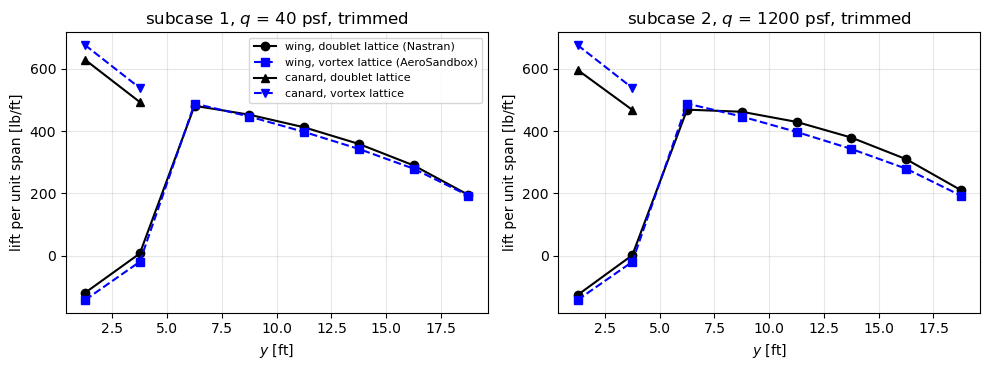

subcase 1, wing strip loads [lb]:
  DLM [-299.   17. 1204. 1132. 1031.  897.  725.  488.]
  VLM [-357.  -50. 1222. 1117.  994.  857.  698.  482.]
subcase 2, wing strip loads [lb]:
  DLM [-317.    3. 1173. 1156. 1074.  948.  775.  526.]
  VLM [-357.  -50. 1221. 1117.  994.  857.  698.  482.]


In [9]:
yw = 1.25 + 2.5*np.arange(8)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, sc in zip(axes, (1, 2)):
    strips_dlm = BOX_FORCES[sc][8:].reshape(8, 4).sum(axis=1)/2.5
    strips_vlm = FB[sc][8:].reshape(8, 4).sum(axis=1)/2.5
    ax.plot(yw, strips_dlm, 'ko-', label='wing, doublet lattice (Nastran)')
    ax.plot(yw, strips_vlm, 'bs--', label='wing, vortex lattice (AeroSandbox)')
    ax.plot(yw[:2], BOX_FORCES[sc][:8].reshape(2, 4).sum(axis=1)/2.5, 'k^-',
            label='canard, doublet lattice')
    ax.plot(yw[:2], FB[sc][:8].reshape(2, 4).sum(axis=1)/2.5, 'bv--',
            label='canard, vortex lattice')
    ax.set_title('subcase %d, $q$ = %.0f psf, trimmed' % (sc, Q_SC[sc]))
    ax.set_xlabel('$y$ [ft]')
    ax.set_ylabel('lift per unit span [lb/ft]')
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
for sc in (1, 2):
    print('subcase %d, wing strip loads [lb]:\n  DLM %s\n  VLM %s' % (
        sc, np.array2string(BOX_FORCES[sc][8:].reshape(8, 4).sum(axis=1), precision=0),
        np.array2string(FB[sc][8:].reshape(8, 4).sum(axis=1), precision=0)))

In subcase 1, the rigid vortex lattice and the doublet lattice agree on the
shape of the span loading, including the negative lift of the wing root in the
downwash of the canard; the vortex lattice puts 8% more load on the canard
(3038 lb against 2807 lb), and correspondingly less on the wing. In
subcase 2, the doublet-lattice loads include the elastic deformation of the
forward-swept wing, which twists the tip nose-up (wash-in) and moves lift
outboard, unloading the canard (2663 lb); the one-way analysis here is rigid
and cannot show this: its trimmed loads are nearly the same in both
subcases.

Inertia relief with the AeroSandbox loads
---

The trimmed vortex-lattice forces, at the vortex centres, are moved to the
box centres with their moments and transferred with SPLINE2 1501 and 1601,
as the published ones, and the inertia relief is solved with the support at
GRID 90. The transferred loads have the resultant force and moment of the
vortex-lattice forces to round-off, and they are balanced by the trim: the
accelerations, $\boldsymbol{\Phi}^\top \boldsymbol{F}_{tot}$ and the
reactions vanish to round-off, and element 101 carries the weight of GRID 97
only.

In [10]:
resB = {}
for sc in (1, 2):
    # the forces act at the vortex centres p0, moved to the box centres
    fa = aero_loads_spline(FB[sc], pts=p0)
    dres = abs(resultant(model, fa, xcg_pt) - resultant_aero(FB[sc], p0)).max()
    out = solve_inertia_relief(model, fa + fw)
    bf = bar_forces(model, out['ufull'])
    print('subcase %d: accelerations %s, |Phi^T F_tot| = %.1e lb, reactions at GRID 90 %s'
          % (sc, np.array2string(out['acc'], precision=1),
             abs(out['Phi'].T @ out['ftot']).max(), np.array2string(out['Rref'], precision=1)))
    print('  element 101: M1A = %.2e, M1B = %.6e lb ft, V1 = %.6e lb'
          % tuple(bf[101][:3]))
    print('  |resultant transferred - resultant of the VLM forces| = %.1e' % dres)
    assert dres < 1e-10*W*c_ref
    assert abs(out['acc']).max() < 1e-10*G_ACC
    assert abs(out['Phi'].T @ out['ftot']).max() < 1e-9*W
    assert abs(out['Rref']).max() < 1e-9*W
    assert np.allclose(bf[101], [0., -1.5e4, 1.5e3, 0.], rtol=0, atol=1e-9*1.5e4)
    resB[sc] = out

subcase 1: accelerations [ 4.3e-15 -1.4e-14], |Phi^T F_tot| = 2.7e-12 lb, reactions at GRID 90 [-3.6e-12  7.3e-11]
  element 101: M1A = 3.64e-12, M1B = -1.500000e+04 lb ft, V1 = 1.500000e+03 lb
  |resultant transferred - resultant of the VLM forces| = 5.4e-11


subcase 2: accelerations [ 1.4e-14 -1.4e-14], |Phi^T F_tot| = 4.5e-12 lb, reactions at GRID 90 [0.0e+00 6.5e-11]
  element 101: M1A = 1.46e-11, M1B = -1.500000e+04 lb ft, V1 = 1.500000e+03 lb
  |resultant transferred - resultant of the VLM forces| = 7.3e-11


Comparison with the published results
---

Displacements relative to GRID 90 (p. 203) and bar forces (p. 204), for
the two subcases: Nastran; A, the published doublet-lattice box forces
transferred with SPLINE2 (relative difference to Nastran, asserted below
$10^{-5}$); C, the same forces transferred with Eq. (5) plus the moments of
the offsets; B, the trimmed vortex-lattice loads transferred with SPLINE2.
Measured agreement:

- A agrees with Nastran to the printed digits, within $10^{-6}$;
- C differs from Nastran only by the load transfer: about 10% at the nose, up
  to about 25% for the shear of element 103, the torque of element 110 and
  the small deflection of GRID 110;
- B differs from Nastran only by the aerodynamic model: in subcase 1
  (quasi-rigid), the vortex and doublet lattices differ by the canard share
  above, and B is within about 11% of Nastran; in subcase 2, the rigid vortex
  lattice also misses the aeroelastic redistribution, and B is up to about
  16% below Nastran for the wing.

The values of B and C are shown, not asserted: they measure the aerodynamic
model and the load transfer, not the structural model, which Checks 1 and 2
and A verify.

In [11]:
rows = [('w 97', 97, 0), ('r_y 97', 97, 2), ('w 100', 100, 0), ('r_y 100', 100, 2),
        ('w 110', 110, 0), ('w 120', 120, 0), ('r_x 120', 120, 1), ('r_y 120', 120, 2),
        ('w 121', 121, 0)]
frows = [('103 M1A', 103, 0), ('103 M1B', 103, 1), ('103 V1', 103, 2),
         ('110 M1A', 110, 0), ('110 V1', 110, 2), ('110 T', 110, 3),
         ('120 M1A', 120, 0), ('120 V1', 120, 2), ('120 T', 120, 3)]
for sc in (1, 2):
    print('subcase %d, q = %.0f psf' % (sc, Q_SC[sc]))
    print('  %-9s %12s %12s %9s %8s %8s' % ('', 'Nastran', 'A', 'A/N-1', 'C/N-1', 'B/N-1'))
    uA, uB, uC = resA[sc]['ufull'], resB[sc]['ufull'], resC[sc]['ufull']
    for lab, g, k in rows:
        n = DISP_PUB[sc][g][k]
        a, b, cc = (u_[DOF*idx[g] + 2 + k] for u_ in (uA, uB, uC))
        print('  %-9s %12.4e %12.4e %+8.0e %+7.1f%% %+7.1f%%' % (
            lab, n, a, a/n - 1, 100*(cc/n - 1), 100*(b/n - 1)))
        assert abs(a/n - 1) < 1e-5
    bA, bB, bC = (bar_forces(model, u_) for u_ in (uA, uB, uC))
    for lab, e, k in frows:
        n = BAR_PUB[sc][e][k]
        if np.isnan(n):
            continue
        a, b, cc = bA[e][k], bB[e][k], bC[e][k]
        print('  %-9s %12.4e %12.4e %+8.0e %+7.1f%% %+7.1f%%' % (
            lab, n, a, a/n - 1, 100*(cc/n - 1), 100*(b/n - 1)))
        assert abs(a/n - 1) < 1e-5

subcase 1, q = 40 psf
                 Nastran            A     A/N-1    C/N-1    B/N-1
  w 97       -6.1768e-03  -6.1768e-03   -1e-07   +10.6%    -0.6%
  r_y 97     -6.3201e-04  -6.3201e-04   -2e-07    +8.3%    -0.5%
  w 100      -1.0660e-02  -1.0660e-02   +3e-07    +2.4%    -3.6%
  r_y 100     1.6888e-03   1.6888e-03   +4e-08    -3.8%    -4.7%
  w 110      -2.4208e-03  -2.4208e-03   -9e-07   +23.6%    +1.1%
  w 120       2.5547e-02   2.5547e-02   +1e-07    -9.5%    -5.6%
  r_x 120     1.2629e-03   1.2629e-03   -2e-07   -13.3%    -4.3%
  r_y 120     3.2557e-03   3.2557e-03   -1e-07    -7.9%    -5.5%
  w 121       3.3686e-02   3.3686e-02   -7e-08    -9.1%    -5.6%
  103 M1A    -2.1402e+04  -2.1402e+04   -1e-07    -0.4%    -2.8%
  103 M1B    -4.3235e+04  -4.3235e+04   +3e-08   -13.2%    -6.8%
  103 V1      2.1833e+03   2.1833e+03   +2e-07   -25.9%   -10.7%
  110 M1A     5.7961e+04   5.7961e+04   -3e-08    -5.8%    -5.3%
  110 V1      3.8998e+03   3.8998e+03   +9e-08   -18.3%    -4.5%
  

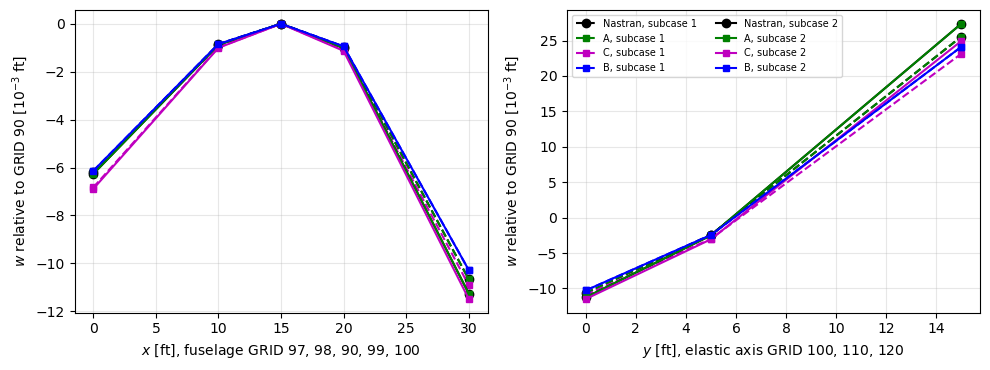

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
fus = [97, 98, 90, 99, 100]
xf = [GRIDS[g][0] for g in fus]
wingg = [100, 110, 120]
yw_ = [GRIDS[g][1] for g in wingg]
for sc, ls in ((1, '--'), (2, '-')):
    pub = [0. if g == 90 else DISP_PUB[sc][g][0] for g in fus]
    axes[0].plot(xf, 1e3*np.array(pub), 'k' + ls + 'o', label='Nastran, subcase %d' % sc)
    axes[1].plot(yw_, 1e3*np.array([DISP_PUB[sc][g][0] for g in wingg]), 'k' + ls + 'o',
                 label='Nastran, subcase %d' % sc)
    for res, col, lab in ((resA, 'g', 'A'), (resC, 'm', 'C'), (resB, 'b', 'B')):
        u = res[sc]['ufull']
        axes[0].plot(xf, 1e3*u[[DOF*idx[g] + 2 for g in fus]], col + ls + 's', ms=4,
                     label='%s, subcase %d' % (lab, sc))
        axes[1].plot(yw_, 1e3*u[[DOF*idx[g] + 2 for g in wingg]], col + ls + 's', ms=4,
                     label='%s, subcase %d' % (lab, sc))
axes[0].set_xlabel('$x$ [ft], fuselage GRID 97, 98, 90, 99, 100')
axes[1].set_xlabel('$y$ [ft], elastic axis GRID 100, 110, 120')
for ax in axes:
    ax.set_ylabel('$w$ relative to GRID 90 [10$^{-3}$ ft]')
    ax.grid(True, alpha=0.3)
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

Summary
---

- The `BeamC` model built from the bulk data of HA144A, with the rigid bars
  as a transformation of the degrees of freedom and shear-rigid beams,
  reproduces the grid point weight generator (weight 8000 lb, centre of
  gravity 2.181625 ft aft of GRID 90, pitch inertia 8.928944e5 lb ft$^2$ about
  it, the whole matrix MO) and, loaded by the nodal loads in equilibrium with
  the published bar forces, the published displacements relative to GRID 90
  to the 7 printed digits (subcases 2 and 3).
- Inertia relief with the reference support at GRID 90 (SUPORT 90 35) and the
  function `pyfe3d.solver.apply_inertia_relief` gives, for every trimmed load set,
  vanishing rigid-body accelerations, $\boldsymbol{\Phi}^\top
  \boldsymbol{F}_{tot} = \boldsymbol{0}$, zero reactions, and the forces of
  element 101, $M_{1B} = -1.5 \times 10^4$ lb ft and $V_1 = 1500$ lb.
- The linear splines of the deck, SPLINE2 1501 and 1601, implemented from
  their theory (Rodden and Johnson 1994, pp. 33-43) and entry (Quick
  Reference Guide, pp. 3137-3138), transfer the published doublet-lattice box
  forces, applied as Nastran applies them at the box centres with their
  moments about the midchord, such that all published bar forces and
  displacements are reproduced to the printed digits (relative differences
  below $10^{-6}$), in both subcases. The transfer conserves the resultant
  force and moment through the rigid arms of the spline; the forces at the
  quarter chord instead change element 103 by up to $2 \times 10^{-3}$, and
  the ratio DTOR changes the transfer, contrary to p. 108 of the guide.
- The inverse-distance load transfer of Gryszka and Castro (2026), Eq. (5),
  conserves the force; for a stick model the moments of the offsets must be
  added to conserve the pitching moment, otherwise the load set is no longer
  trimmed and the airplane accelerates in pitch. With the moments, the
  results differ from Nastran's by up to about 25%, through the distribution
  of the loads alone.
- The vortex lattice method of AeroSandbox gives forces at the bound-vortex
  midpoints and no panel moments; their moments are transported to the box
  centres and through the splines, with the resultant conserved to
  round-off. The trim angles differ from Nastran's mainly through the
  uniform Prandtl-Glauert factor, which does not change the trimmed loads. In
  the quasi-rigid subcase 1, the span loadings agree in shape and the
  structural results are within about 11% of Nastran's; in subcase 2, the
  one-way rigid analysis misses the aeroelastic wash-in of the forward-swept
  wing, and the wing deflections and loads are up to about 16% lower than
  Nastran's elastic trim.